# Shapes3D — experiments on trained models

1. **Catalog**: every model in `outputs/models/shapes3d_*`, with its settings and final test metrics.
2. **Choose** one with `CHOICE`, then *Run All* (or run from the choice cell down).
3. **Experiments** on that model, all on **held-out** test images (the exact split the model never trained on):

| § | experiment |
|---|---|
| E1 | training curves |
| E2 | reconstructions and prior samples |
| E3 | concept prediction accuracy, per concept |
| E4 | interactive generation (sliders) |
| E5 | concept traversals |
| E6 | editing real images |
| E7 | **intervention success**: set a concept, does the image really change, and do the others stay put? |
| E8 | latent interpolation between two real images |
| E9 | the chosen model next to all the others |

To train more models: `sbatch run_shapes3d.sh` on the cluster, then rsync `outputs/models/shapes3d_*` here.

In [14]:
%matplotlib inline
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import ipywidgets as W
from IPython.display import display

from cbmc.data.shapes3d import ConceptSpace, FACTORS, NOMINAL, get_held_out
from scripts.train_shapes3d_gen import load, list_saved, get_device

DEVICE = get_device()
CASE = {"vae": "baseline (no concepts)", "cbm": "CBM", "cem": "Case 3.5 (ours)",
        "cem_linear": "CEM-linear", "categorical": "Case 2", "binned": "Case 3"}

def show(imgs, titles=None, nrow=8, size=1.6, suptitle=None):
    imgs = imgs.clamp(0, 1).cpu()
    n = len(imgs); ncol = min(nrow, n); nr = (n + ncol - 1) // ncol
    fig, axes = plt.subplots(nr, ncol, figsize=(ncol * size, nr * size), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            ax.imshow(imgs[i].permute(1, 2, 0).numpy())
            if titles: ax.set_title(titles[i], fontsize=7)
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

## Catalog of trained models

In [15]:
def describe(run):
    ck = torch.load(run / "model.pt", map_location="cpu", weights_only=False)
    tr, bb, sp = ck["train_cfg"], ck["backbone_cfg"], ck["concept_space"]
    row = {"folder": run.name, "model": ck["model_name"], "case": CASE.get(ck["model_name"], ""),
           "epochs": ck.get("epoch") or tr["epochs"], "latent": bb["latent_dim"],
           "mode": sp["mode"] if sp else "-",
           "n_bins": sp["n_bins"] if sp and sp["mode"] == "binned" else "",
           "n_samples": (ck.get("data_cfg") or {}).get("n_samples"),
           "concept_w": tr["concept_weight"], "cycle_w": tr.get("cycle_weight", 0.0)}
    m = pd.read_csv(run / "metrics.csv").iloc[-1] if (run / "metrics.csv").exists() else {}
    for k in ["test_recon", "test_concept_mse", "test_concept_acc"]:
        row[k] = round(float(m[k]), 4) if k in m and not pd.isna(m[k]) else None
    return row

RUNS = list_saved()
CATALOG = pd.DataFrame([describe(r) for r in RUNS])
CATALOG.index.name = "#"
CATALOG

,folder,model,case,epochs,latent,mode,n_bins,n_samples,concept_w,cycle_w,test_recon,test_concept_mse,test_concept_acc
#,,,,,,,,,,,,,
0,shapes3d_binned,binned,Case 3,30,32,binned,5,200000,100.0,100.0,3459.3504,0.0136,0.5757
1,shapes3d_binned_noshape,binned,Case 3,30,32,binned,5,200000,100.0,100.0,3459.7943,0.0163,0.4915
2,shapes3d_categorical,categorical,Case 2,30,32,categorical,,200000,100.0,100.0,3462.5352,0.0001,0.9992
3,shapes3d_categorical_noshape,categorical,Case 2,30,32,categorical,,200000,100.0,100.0,3464.1056,0.0000,0.9996
4,shapes3d_cbm,cbm,CBM,30,32,continuous,,200000,100.0,100.0,3471.1922,0.0005,0.9999
5,shapes3d_cbm_noshape,cbm,CBM,30,32,continuous,,200000,100.0,100.0,3805.8889,0.0165,0.8305
6,shapes3d_cem,cem,Case 3.5 (ours),30,32,continuous,,200000,100.0,100.0,4980.0607,0.0222,0.8746
7,shapes3d_cem_linear,cem_linear,CEM-linear,30,32,continuous,,200000,100.0,100.0,3465.3040,0.0009,0.9971
8,shapes3d_cem_linear_noshape,cem_linear,CEM-linear,30,32,continuous,,200000,100.0,100.0,3465.3438,0.0006,0.9991


Last-epoch sample grid of each model (rows: test images · reconstructions · prior samples).

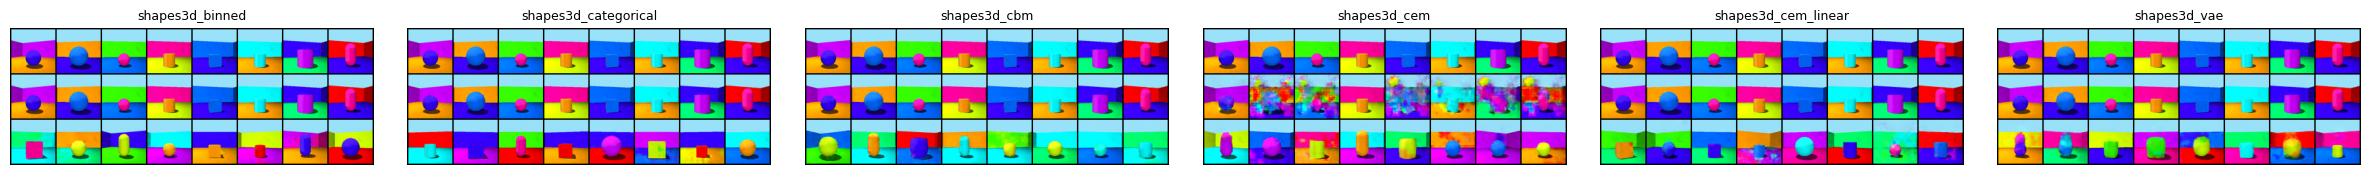

In [3]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(4 * len(RUNS), 1.7), squeeze=False)
for ax, run in zip(axes[0], RUNS):
    last = sorted((run / "samples").glob("epoch_*.png"))
    if last: ax.imshow(plt.imread(last[-1]))
    ax.set_title(run.name, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## Choose a model

In [9]:
# ============================ CHOOSE HERE ============================
CHOICE    = "shapes3d_cem_linear"     # a folder name, a row number of the catalog, or a model name ("cem", "binned", ...)
JUDGE     = "auto"             # model that READS concepts off generated images in E7; "auto" = the most
                               # accurate other model with concepts (by test_concept_acc)
N_TEST    = 5_000              # held-out images to load (~25 s the first time; cached afterwards)
SEED_Z    = 0
# =====================================================================

def resolve_run(choice):
    if isinstance(choice, int):
        return RUNS[choice]
    hits = [r for r in RUNS if r.name == choice] or \
           [r for r in RUNS if r.name == f"shapes3d_{choice}"] or \
           [RUNS[i] for i in CATALOG.index[CATALOG["model"] == choice]]
    if not hits:
        raise ValueError(f"{choice!r} not found; choose from {[r.name for r in RUNS]}")
    return hits[0]

RUN = resolve_run(CHOICE)
gen = load(RUN, device=DEVICE)
print(f"chosen: {RUN.name}  ->  {gen}   [{CASE.get(gen.name, '')}]")

# held-out test images of the split this model was trained with
_d = gen.data_cfg or {}
_key = (_d.get("n_samples"), _d.get("seed", 42), N_TEST)
if globals().get("_TEST_KEY") != _key:
    from cbmc.data.shapes3d import FACTOR_NAMES
    X_TEST, C_TEST, _ = get_held_out(n_samples=_key[0], seed=_key[1], max_images=N_TEST,
                                     concepts=FACTOR_NAMES)
    _TEST_KEY = _key
    print(f"loaded {len(X_TEST)} held-out images")
NAMES = gen.space.names if gen.has_concepts else []
C_SEL = C_TEST[:, [list(FACTORS).index(n) for n in NAMES]] if NAMES else None

chosen: shapes3d_cem_linear  ->  Generator(cem_linear, concepts=['floor_hue', 'wall_hue', 'object_hue', 'scale', 'shape', 'orientation'], mode=continuous)   [CEM-linear]


## E1 · Training curves

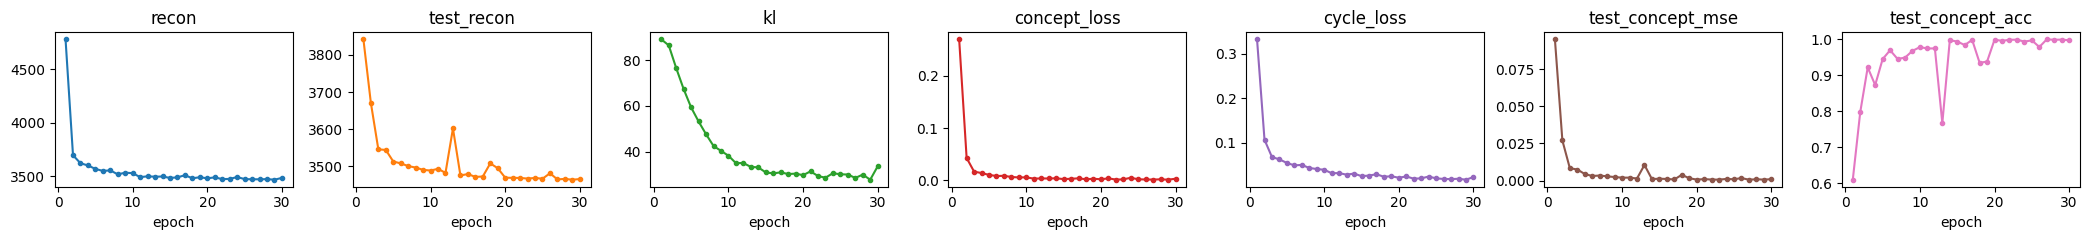

In [10]:
m = pd.read_csv(RUN / "metrics.csv")
cols = [c for c in ["recon", "test_recon", "kl", "concept_loss", "cycle_loss",
                    "test_concept_mse", "test_concept_acc"] if c in m and m[c].abs().sum() > 0]
m.plot(x="epoch", y=cols, subplots=True, layout=(1, len(cols)), figsize=(3 * len(cols), 2.5),
       legend=False, title=cols, marker=".")
plt.tight_layout(); plt.show()

## E2 · Reconstructions and prior samples
Row 1: held-out images · Row 2: reconstructions · Row 3: samples from $z\sim\mathcal N(0,I)$.

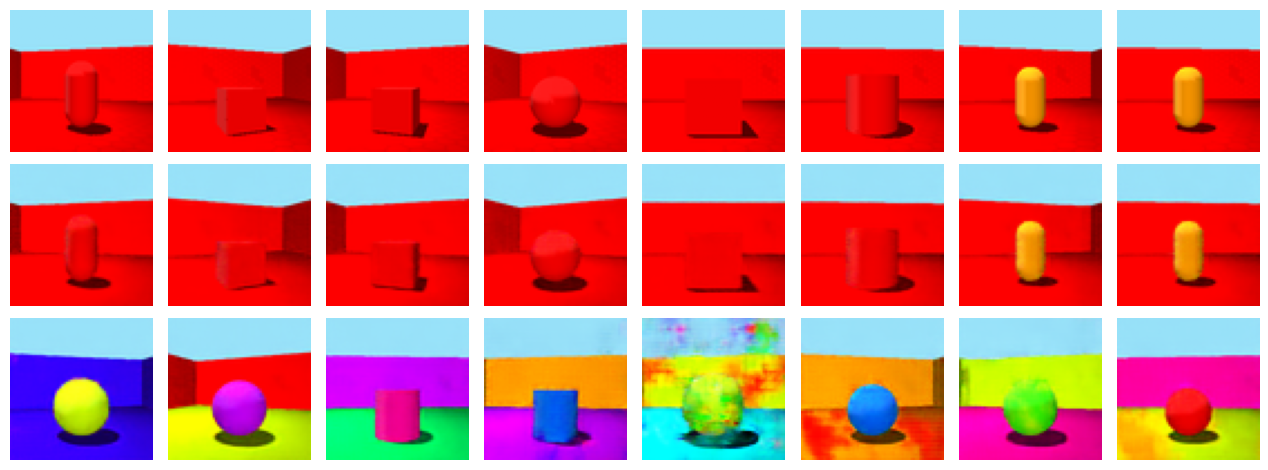

In [11]:
x8 = X_TEST[:8]
show(torch.cat([x8.float() / 255, gen.reconstruct(x8), gen.generate(8, seed=SEED_Z)]), nrow=8)

## E3 · Concept prediction on held-out images
Accuracy = the predicted value rounds to the true **native** state (10 hues, 8 scales, 4 shapes, 15 orientations), so all models are scored on the same scale; for `binned` this includes the quantisation cost. MSE is in [-1, 1] units.

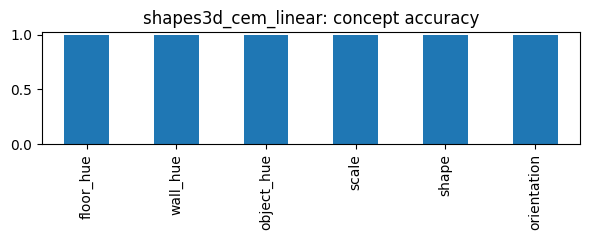

,accuracy,mse
floor_hue,1.000000,0.001600
wall_hue,0.999200,0.001100
object_hue,0.996200,0.001400
scale,0.994800,0.000700
shape,0.999400,0.000400
orientation,0.991600,0.000600
mean,0.996867,0.000967


In [12]:
def batched(fn, x, bs=500):
    return torch.cat([fn(x[i:i + bs]) for i in range(0, len(x), bs)])

if gen.has_concepts:
    pred = batched(gen.predict_concepts, X_TEST)
    native, unit = ConceptSpace(NAMES, "categorical"), ConceptSpace(NAMES, "continuous")
    acc = (native.encode(pred) == native.encode(C_SEL)).float().mean(0)
    mse = ((unit.encode(pred) - unit.encode(C_SEL)) ** 2).mean(0)
    E3 = pd.DataFrame({"accuracy": acc.numpy(), "mse": mse.numpy()}, index=NAMES).round(4)
    E3.loc["mean"] = E3.mean()
    fig, ax = plt.subplots(figsize=(6, 2.5))
    E3["accuracy"].drop("mean").plot.bar(ax=ax, ylim=(0, 1.02), title=f"{RUN.name}: concept accuracy")
    plt.tight_layout(); plt.show()
    display(E3)
else:
    print("plain VAE: no concepts")

## E4 · Interactive generation
Fixed `z` (seed slider), one slider per concept; **auto** = leave the concept to the model. Continuous models accept in-between values too.
For the plain VAE the sliders move the first latent dimensions.

In [ ]:
out = W.Output()
seed_w = W.IntSlider(value=SEED_Z, min=0, max=200, description="z seed", continuous_update=False)
if gen.has_concepts:
    sliders = {n: W.SelectionSlider(options=[("auto", "auto")] + [(f"{v:.3g}", float(v)) for v in gen.space.slider_values(n)],
                                    value="auto", description=n, continuous_update=False,
                                    layout=W.Layout(width="420px"), style={"description_width": "90px"})
               for n in NAMES}
else:
    sliders = {f"z[{i}]": W.FloatSlider(value=0.0, min=-3, max=3, step=0.25, description=f"z[{i}]",
                                        continuous_update=False) for i in range(min(6, gen.latent_dim))}

def render(*_):
    with out:
        out.clear_output(wait=True)
        z = gen.prior(1, seed_w.value)
        if gen.has_concepts:
            chosen = {k: s.value for k, s in sliders.items() if s.value != "auto"}
            img, used = gen.generate(z=z, concepts=chosen, return_concepts=True)
            title = "  ".join(f"{k}={v:.2g}" for k, v in zip(NAMES, used[0].tolist()))
        else:
            for i, s in enumerate(sliders.values()): z[0, i] = s.value
            img, title = gen.generate(z=z), ""
        fig, ax = plt.subplots(figsize=(3.2, 3.2))
        ax.imshow(img[0].permute(1, 2, 0).numpy()); ax.axis("off"); ax.set_title(title, fontsize=7, wrap=True)
        plt.show()

for w in [seed_w, *sliders.values()]: w.observe(render, names="value")
display(W.HBox([W.VBox([seed_w, *sliders.values()]), out])); render()

## E5 · Concept traversals
One fixed `z` per row; each row sweeps one concept.

In [ ]:
if gen.has_concepts:
    for n in NAMES:
        vals = gen.space.slider_values(n)
        if len(vals) > 10: vals = [vals[round(i * (len(vals) - 1) / 9)] for i in range(10)]
        show(gen.traverse(n, vals, seed=SEED_Z), titles=[f"{v:.2g}" for v in vals], nrow=len(vals), size=1.2, suptitle=n)

## E6 · Edit real images
Encode held-out images, change some concepts, decode.

In [ ]:
IDX  = [0, 1, 2, 3]
EDIT = {"object_hue": 0.0, "shape": 3.0, "scale": 1.25}     # raw values; any subset of the concepts

if gen.has_concepts:
    edits = [{k: v} for k, v in EDIT.items()] + [EDIT]
    labels = ["original", "recon"] + [", ".join(f"{k}={v}" for k, v in e.items()) for e in edits]
    for i in IDX:
        x1 = X_TEST[i:i + 1]
        show(torch.cat([x1.float() / 255, gen.reconstruct(x1)] + [gen.reconstruct(x1, e) for e in edits]),
             titles=labels, nrow=len(labels), size=1.4)

## E7 · Intervention success
For every concept and every native value: sample `N_PER_VALUE` random `z`, generate with that concept **set**, and let an independent **judge** model read the concepts back from the generated images.

* **success**: the judge reads back the value we set (native state).
* **preservation**: the *other* concepts read the same as in the un-intervened image from the same `z`.

The judge is a different trained model; its own held-out accuracy is printed so you know how far to trust it.

In [ ]:
N_PER_VALUE = 64

if gen.has_concepts:
    cands = CATALOG[(CATALOG.folder != RUN.name) & CATALOG.test_concept_acc.notna()]
    judge_run = resolve_run(cands.sort_values("test_concept_acc").folder.iloc[-1] if JUDGE == "auto" else JUDGE)
    judge = load(judge_run, device=DEVICE)
    jn = ConceptSpace(judge.space.names, "categorical")
    j_acc = (jn.encode(batched(judge.predict_concepts, X_TEST[:2000])) ==
             jn.encode(C_TEST[:2000, [list(FACTORS).index(n) for n in judge.space.names]])).float().mean().item()
    print(f"judge: {judge_run.name}  (held-out concept accuracy {j_acc:.3f})")

    native = ConceptSpace(NAMES, "categorical")
    jcol = [judge.space.names.index(n) for n in NAMES]
    z = gen.prior(N_PER_VALUE, SEED_Z)
    base = native.encode(judge.predict_concepts(gen.generate(z=z))[:, jcol])
    rows = []
    for ci, n in enumerate(NAMES):
        lo, hi, k = FACTORS[n]
        for v in np.linspace(lo, hi, k):
            read = native.encode(judge.predict_concepts(gen.generate(z=z, concepts={n: float(v)}))[:, jcol])
            target = native.encode(torch.full((1, len(NAMES)), float(v)))[0, ci]   # native state of v
            others = [j for j in range(len(NAMES)) if j != ci]
            rows.append({"concept": n, "value": round(float(v), 3),
                         "success": (read[:, ci] == target).float().mean().item(),
                         "preservation": (read[:, others] == base[:, others]).float().mean().item() if others else np.nan})
    E7 = pd.DataFrame(rows)
    E7_SUMMARY = E7.groupby("concept", sort=False)[["success", "preservation"]].mean().round(3)
    E7_SUMMARY.loc["mean"] = E7_SUMMARY.mean()
    fig, axes = plt.subplots(1, len(NAMES), figsize=(2.6 * len(NAMES), 2.4), sharey=True)
    for ax, n in zip(np.atleast_1d(axes), NAMES):
        d = E7[E7.concept == n]
        ax.plot(d.value, d.success, "o-", label="success"); ax.plot(d.value, d.preservation, "s--", label="preservation")
        ax.set_title(n, fontsize=9); ax.set_ylim(-0.02, 1.02)
    np.atleast_1d(axes)[0].legend(fontsize=7); plt.tight_layout(); plt.show()
    display(E7_SUMMARY)
else:
    print("plain VAE: no concepts to intervene on")

## E8 · Latent interpolation between two held-out images

In [ ]:
A, B, STEPS = 0, 5, 8
za, zb = gen.encode(X_TEST[A:A + 1]), gen.encode(X_TEST[B:B + 1])
ts = torch.linspace(0, 1, STEPS, device=za.device)
zs = torch.cat([(1 - t) * za + t * zb for t in ts])
show(torch.cat([X_TEST[A:A + 1].float() / 255, gen.generate(z=zs), X_TEST[B:B + 1].float() / 255]),
     titles=["A"] + [f"t={t:.2f}" for t in ts.tolist()] + ["B"], nrow=STEPS + 2, size=1.3)

## E9 · The chosen model next to all the others
Same `z`, same interventions.

In [ ]:
COMPARE = [{}, {"shape": 0.0}, {"shape": 2.0}, {"object_hue": 0.0}, {"object_hue": 0.6},
           {"wall_hue": 0.3}, {"scale": 0.75}, {"scale": 1.25}, {"orientation": 30.0}]
for run in RUNS:
    g = gen if run == RUN else load(run, device=DEVICE)
    z1 = g.prior(1, SEED_Z)
    imgs = [g.generate(z=z1, concepts={k: v for k, v in c.items() if g.has_concepts and k in g.space.names} or None)
            for c in COMPARE]
    show(torch.cat(imgs), titles=[", ".join(f"{k}={v}" for k, v in c.items()) or "prior" for c in COMPARE],
         nrow=len(COMPARE), size=1.25, suptitle=("▶ " if run == RUN else "") + run.name)